In [28]:
data = {
    "area": [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800],
    "bedrooms": [2, 2, 3, 3, 4, 4, 4, 5],
    "price": [30, 35, 45, 52, 60, 65, 73, 82]
}

In [29]:
import pandas as pd 
df = pd.DataFrame(data)


In [30]:
df.corr(numeric_only=True)

,area,bedrooms,price
area,1.000000,0.964249,0.999236
bedrooms,0.964249,1.000000,0.972808
price,0.999236,0.972808,1.000000


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   area      8 non-null      int64
 1   bedrooms  8 non-null      int64
 2   price     8 non-null      int64
dtypes: int64(3)
memory usage: 324.0 bytes


In [32]:
x = df.drop(columns="price")
y = df["price"]

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,r2_score,root_mean_squared_error

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

modle = LinearRegression()
modle.fit(x_train, y_train)
y_pred = modle.predict(x_test)

print(mean_absolute_error(y_test, y_pred))
print(r2_score(y_test, y_pred))
print(root_mean_squared_error(y_test, y_pred))

0.08391608391607974
0.9999632690541781
0.09090909090908912


In [44]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import webbrowser, os

# plane from YOUR trained model
A, B = np.meshgrid(
    np.linspace(x["area"].min(), x["area"].max(), 20),
    np.linspace(x["bedrooms"].min(), x["bedrooms"].max(), 20),
)
grid = pd.DataFrame({"area": A.ravel(), "bedrooms": B.ravel()})
Z = modle.predict(scaler.transform(grid)).reshape(A.shape)

fig = go.Figure()
fig.add_trace(go.Scatter3d(x=x["area"], y=x["bedrooms"], z=y, mode="markers",
                           marker=dict(size=6, color="blue"), name="Actual values"))
fig.add_trace(go.Surface(x=A, y=B, z=Z, opacity=0.6, colorscale="Reds",
                         showscale=False, name="Regression plane"))
fig.update_layout(title="Actual values and Regression plane",
                  scene=dict(xaxis_title="Area", yaxis_title="Bedrooms", zaxis_title="Price"))

# save and open in Brave
fig.write_html("plot3d.html")
webbrowser.register("brave", None, webbrowser.BackgroundBrowser("brave-browser"))
webbrowser.get("brave").open("file://" + os.path.abspath("plot3d.html"))

True

Opening in existing browser session.


[24085:24085:0100/000000.421091:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)
[1:1:0100/000000.424517:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)


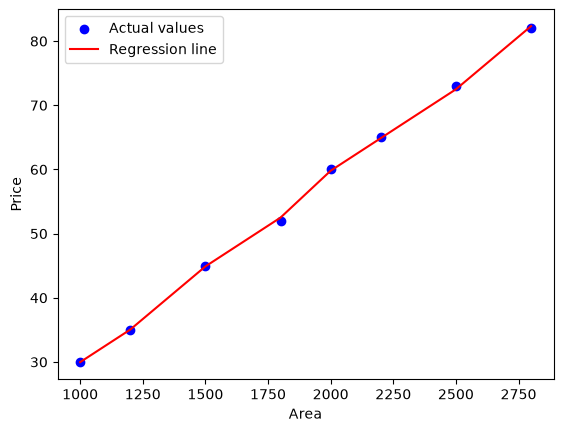

In [43]:
import matplotlib.pyplot as plt

plt.scatter(x["area"], y, color="blue", label="Actual values")
plt.plot(x["area"], modle.predict(scaler.transform(x)), color="red", label="Regression line")
plt.xlabel("Area")
plt.ylabel("Price")
plt.legend()
plt.show()

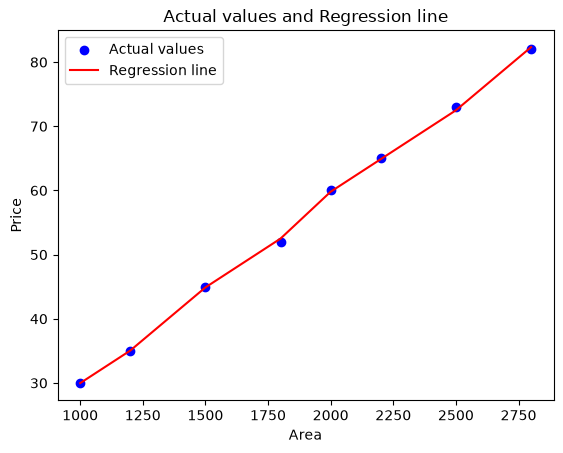

In [41]:
import matplotlib.pyplot as plt

y_line = modle.predict(scaler.transform(x))   # your model's predictions for all houses

plt.scatter(x["area"], y, color="blue", label="Actual values")
plt.plot(x["area"], y_line, color="red", label="Regression line")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Actual values and Regression line")
plt.legend()
plt.show()

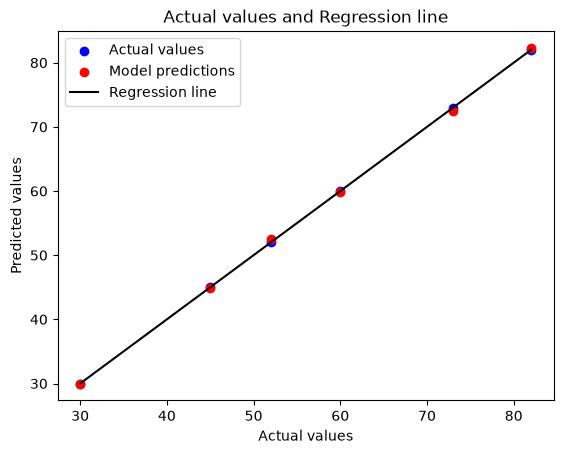

In [39]:
import matplotlib.pyplot as plt

# predictions from YOUR trained model on the training data
train_pred = modle.predict(x_train)

# actual values (blue)
plt.scatter(y_train, y_train, color="blue", label="Actual values")

# model predictions (red)
plt.scatter(y_train, train_pred, color="red", label="Model predictions")

# regression line
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color="black", label="Regression line")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual values and Regression line")
plt.legend()
plt.show()

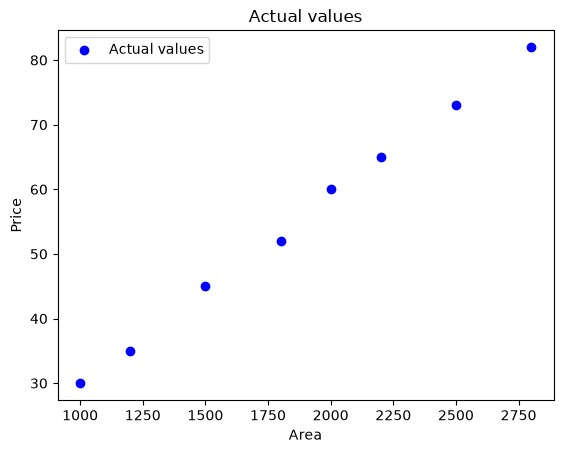

In [37]:
import matplotlib.pyplot as plt

plt.scatter(df["area"], df["price"], color="blue", label="Actual values")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Actual values")
plt.legend()
plt.show()

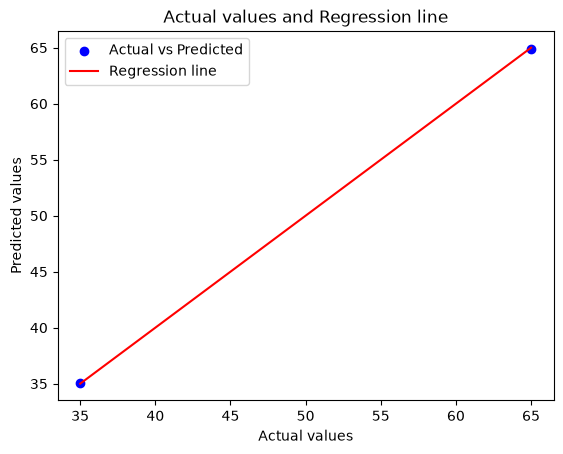

In [38]:
import matplotlib.pyplot as plt

# actual values (blue) and model predictions on the test set
plt.scatter(y_test, y_pred, color="blue", label="Actual vs Predicted")

# regression line (red): perfect-fit line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", label="Regression line")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual values and Regression line")
plt.legend()
plt.show()

In [22]:
dataTwo = {
    "hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "pass": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
}

In [23]:
dfTwo = pd.DataFrame(dataTwo)

In [ ]:
xT = dfTwo[["hours"]]
yT = dfTwo["pass"]

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

x_train, x_test, y_train, y_test = train_test_split(xT, yT, test_size=0.20, random_state=42, stratify=yT)


model = LogisticRegression()
model.fit(x_train, y_train)
prediction = model.predict(x_test)

print(accuracy_score(y_test, prediction))

1.0
